<a href="https://colab.research.google.com/github/Irugudandla-priyanka/Plant-Disease-Detection/blob/main/Copy_of_Plant_Disease_Detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras import layers, models
from tensorflow.keras.preprocessing.image import ImageDataGenerator

print("Plant Disease Detection Project")
print("Libraries imported successfully!")
print("TensorFlow version:", tf.__version__)

Plant Disease Detection Project
Libraries imported successfully!
TensorFlow version: 2.21.0


In [ ]:
%pip install importlib-resources

In [ ]:
Kiimport tensorflow_datasets as tfds

print("Loading Plant Village dataset...")

(ds_train, ds_val), ds_info = tfds.load(
    "plant_village",
    split=["train[:80%]", "train[80%:]"],
    as_supervised=True,
    with_info=True
)

print("Dataset loaded successfully!")
print("Number of classes:", ds_info.features["label"].num_classes)
print("Class names:")
print(ds_info.features["label"].names)

Loading Plant Village dataset...


Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]

Generating splits...:   0%|          | 0/1 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/plant_village/incomplete.3TWXG5_1.0.2/plant_village-train.tfrecord-[0-9][0…

Dataset plant_village downloaded and prepared to /root/tensorflow_datasets/plant_village/1.0.2. Subsequent calls will reuse this data.
Dataset loaded successfully!
Number of classes: 38
Class names:
['Apple___Apple_scab', 'Apple___Black_rot', 'Apple___Cedar_apple_rust', 'Apple___healthy', 'Blueberry___healthy', 'Cherry___healthy', 'Cherry___Powdery_mildew', 'Corn___Cercospora_leaf_spot Gray_leaf_spot', 'Corn___Common_rust', 'Corn___healthy', 'Corn___Northern_Leaf_Blight', 'Grape___Black_rot', 'Grape___Esca_(Black_Measles)', 'Grape___healthy', 'Grape___Leaf_blight_(Isariopsis_Leaf_Spot)', 'Orange___Haunglongbing_(Citrus_greening)', 'Peach___Bacterial_spot', 'Peach___healthy', 'Pepper,_bell___Bacterial_spot', 'Pepper,_bell___healthy', 'Potato___Early_blight', 'Potato___healthy', 'Potato___Late_blight', 'Raspberry___healthy', 'Soybean___healthy', 'Squash___Powdery_mildew', 'Strawberry___healthy', 'Strawberry___Leaf_scorch', 'Tomato___Bacterial_spot', 'Tomato___Early_blight', 'Tomato___hea

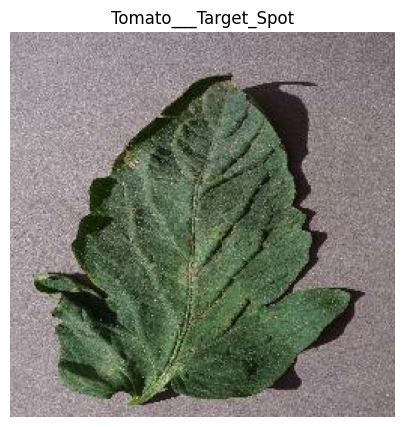

In [ ]:
plt.figure(figsize=(5, 5))

for image, label in ds_train.take(1):
    plt.imshow(image)
    plt.title(ds_info.features["label"].int2str(label.numpy()))
    plt.axis("off")

plt.show()

In [ ]:
IMG_SIZE = 128
BATCH_SIZE = 32

def prepare_image(image, label):
    image = tf.image.resize(image, (IMG_SIZE, IMG_SIZE))
    image = tf.cast(image, tf.float32) / 255.0
    return image, label

train_data = ds_train.map(
    prepare_image,
    num_parallel_calls=tf.data.AUTOTUNE
).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

val_data = ds_val.map(
    prepare_image,
    num_parallel_calls=tf.data.AUTOTUNE
).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

print("Image preprocessing completed!")
print("Image size:", IMG_SIZE, "x", IMG_SIZE)
print("Batch size:", BATCH_SIZE)

Image preprocessing completed!
Image size: 128 x 128
Batch size: 32


In [ ]:
num_classes = ds_info.features["label"].num_classes

model = models.Sequential([
    layers.Input(shape=(128, 128, 3)),

    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(num_classes, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()
print("Plant Disease Detection model created successfully!")

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 38)             │         4,902 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,309,542 (12.62 MB)

 Trainable params: 3,309,542 (12.62 MB)

 Non-trainable params: 0 (0.00 B)

Plant Disease Detection model created successfully!


In [ ]:
EPOCHS = 1

history = model.fit(
    train_data,
    validation_data=val_data,
    epochs=EPOCHS
)

print("Model training completed haa!")

1358/1358 ━━━━━━━━━━━━━━━━━━━━ 907s 667ms/step - accuracy: 0.9381 - loss: 0.1895 - val_accuracy: 0.9326 - val_loss: 0.2331
Model training completed haa!


In [ ]:
loss, accuracy = model.evaluate(val_data)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

340/340 ━━━━━━━━━━━━━━━━━━━━ 68s 198ms/step - accuracy: 0.9326 - loss: 0.2331
Model Accuracy: 93.26 %


In [ ]:
model.save("plant_disease_detection.keras")
print("Model saved successfully!")

Model saved successfully!


In [ ]:
from google.colab import files
files.download("plant_disease_detection.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import os

print(os.path.exists("/content/plant_disease_detection.keras"))
print(os.path.getsize("/content/plant_disease_detection.keras"))

True
39762067


In [ ]:
print(model.count_params())
print(model.input_shape)
print(model.output_shape)

3309542
(None, 128, 128, 3)
(None, 38)


In [ ]:
from google.colab import files
files.download("/content/plant_disease_detection.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
model.save("/content/plant_disease_detection.keras")

print("Model file size:")
print(os.path.getsize("/content/plant_disease_detection.keras"))

Model file size:
39762067


In [ ]:
from google.colab import files
files.download("/content/plant_disease_detection.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>